# 08 · Causal analysis: does the grade mediate the link between IDH and age?

**Motivation.** The regression of notebook 04 found that, without the grade, the mutations explain part of the age at diagnosis, but mostly *because* they recover the grade (IDH1, IDH2 and ATRX). That is a causal statement in disguise: the grade would be a **mediator** between the mutations and the age at diagnosis. This notebook makes the assumptions explicit with a **causal diagram** and estimates how much of the IDH–age association goes through the grade, following the course suggestion (weekly summary of 25 September; *The Effect*, chapters 6 and 13): draw the diagram first, and let it decide which variables to adjust for.

**Exposure:** IDH mutation (IDH1 or IDH2; `IDH_mut`). **Mediator:** grade (GBM = 1). **Outcome:** age at diagnosis (years). **Covariates:** sex and race (white vs other; the other categories are too small to be adjusted for separately, see the leverage problem of notebook 04).

| # | Section |
|---|---|
| 1 | Setup |
| 2 | The causal diagram and its assumptions |
| 3 | Descriptive view: age by IDH status and grade |
| 4 | Regressions with different adjustment sets |
| 5 | Mediation decomposition with bootstrap intervals |
| 6 | Does the effect of IDH differ by grade? |
| 7 | Limitations and summary |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Project root (folder containing src/config.py) not found")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import causal, config, data, plotting, reporting
from src.plotting import NEUTRAL

plotting.set_style()
pd.set_option("display.precision", 3)

df = data.load_processed().copy()
df["IDH_mut"] = ((df["IDH1"] == 1) | (df["IDH2"] == 1)).astype(int)
df["White"] = (df["Race"] == 0).astype(int)
fam = data.diagnosis_family(df)
for k, lab in config.MULTICLASS_LABELS.items():
    df[f"Family_{lab}"] = (fam == k).astype(int)
COV = ["Gender", "White"]
OTHER_GENES = [g for g in config.GENE_COLS if g not in ("IDH1", "IDH2")]
results = {"n": len(df), "n_idh_mut": int(df["IDH_mut"].sum()), "n_idh2_only": int(((df["IDH2"] == 1) & (df["IDH1"] == 0)).sum()),
           "covariates": COV}
print(f"{len(df)} patients; IDH-mutant (IDH1 or IDH2): {df['IDH_mut'].sum()}, of which IDH2 without IDH1: {results['n_idh2_only']}")

839 patients; IDH-mutant (IDH1 or IDH2): 427, of which IDH2 without IDH1: 23


## 2. The causal diagram and its assumptions

Arrows are assumptions about what causes what, not results:
- **IDH → grade.** IDH-mutant gliomas are mostly lower-grade tumours; in the data, GBM is rarely IDH-mutant (EDA).
- **Grade → age at diagnosis.** The kind of tumour influences when it becomes symptomatic and is diagnosed.
- **IDH → age at diagnosis (direct).** Any effect of IDH on the age at diagnosis that does not go through the binary grade (for example, through the histological type).
- **Sex, race → everything.** They are fixed before the tumour arises, so they can only be common causes (confounders), never mediators: adjusting for them is safe.
- **U (dashed): unmeasured causes of the grade and of the age at diagnosis**, such as copy-number alterations missing from the data, or the period in which each patient was diagnosed. If U exists, the *total* effect is still estimable, but the *direct* effect is not, because adjusting for the grade opens the path IDH → grade ← U → age (the grade becomes a **collider**).

The age at diagnosis is treated as an outcome of the tumour biology. The alternative reading, that the age of the patient influences which tumour arises (age → IDH), would reverse the arrow; then the regressions below would still describe associations, but not effects of IDH.

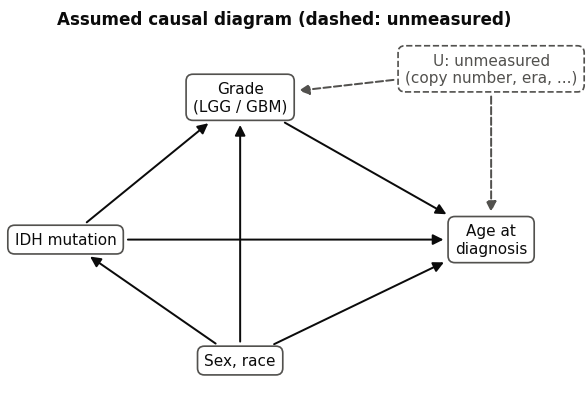

In [2]:
nodes = {"IDH mutation": (0.1, 0.42), "Grade\n(LGG / GBM)": (0.42, 0.82), "Age at\ndiagnosis": (0.88, 0.42),
         "Sex, race": (0.42, 0.08), "U: unmeasured\n(copy number, era, ...)": (0.88, 0.9)}
edges = [("IDH mutation", "Grade\n(LGG / GBM)"), ("Grade\n(LGG / GBM)", "Age at\ndiagnosis"), ("IDH mutation", "Age at\ndiagnosis"),
         ("Sex, race", "IDH mutation"), ("Sex, race", "Grade\n(LGG / GBM)"), ("Sex, race", "Age at\ndiagnosis"),
         ("U: unmeasured\n(copy number, era, ...)", "Grade\n(LGG / GBM)"), ("U: unmeasured\n(copy number, era, ...)", "Age at\ndiagnosis")]
dashed = edges[-2:]
fig, ax = plt.subplots(figsize=(6.4, 4.2))
causal.draw_dag(ax, nodes, edges, dashed=dashed)
ax.set_title("Assumed causal diagram (dashed: unmeasured)")
plotting.save_figure(fig, "causal_dag")
plt.show()

## 3. Descriptive view: age by IDH status and grade

Before any model: the mean age in the four groups. If the grade mediated the whole association, the IDH difference would disappear *within* each grade.

In [3]:
tab = df.groupby(["Grade", "IDH_mut"])["Age_at_diagnosis"].agg(["count", "mean", "std"]).rename(
    index={0: "LGG", 1: "GBM"}, level=0).rename(index={0: "IDH wildtype", 1: "IDH mutant"}, level=1)
display(tab)
overall = df.groupby("IDH_mut")["Age_at_diagnosis"].mean()
results["age_by_idh_grade"] = {f"{g} | {i}": r.to_dict() for (g, i), r in tab.iterrows()}
results["mean_age_by_idh"] = {"wildtype": overall[0], "mutant": overall[1], "difference": overall[1] - overall[0]}
print(f"Mean age: IDH mutant {overall[1]:.1f} vs wildtype {overall[0]:.1f} years (difference {overall[1] - overall[0]:.1f})")
reporting.save_table_tex(tab.reset_index().rename(columns={"IDH_mut": "IDH", "count": "n", "mean": "Mean age", "std": "SD"}),
                         "causal_age_by_group", float_format="{:.1f}", column_format="llrrr")

count    mean     std
Grade IDH_mut                            
LGG   IDH wildtype     85  54.659  12.589
      IDH mutant      402  41.595  12.251
GBM   IDH wildtype    327  62.224  12.261
      IDH mutant       25  40.822  12.307

Mean age: IDH mutant 41.5 vs wildtype 60.7 years (difference -19.1)


WindowsPath('C:/Users/ori/ML/results/tables/causal_age_by_group.tex')

## 4. Regressions with different adjustment sets

OLS of the age at diagnosis with heteroscedasticity-robust (HC3) intervals. Only the coefficient of `IDH_mut` is of interest; what changes between the rows is **what is adjusted for**, and the diagram says what each row estimates:

| Adjustment set | What the IDH coefficient estimates under the diagram |
|---|---|
| Sex, race | **Total effect** of IDH (all paths) |
| + grade | **Direct effect** not through the grade (valid only if there is no U) |
| + histological family | Effect not through grade *or* histological type: the family is also a consequence of IDH, so this removes even more of the effect (over-adjustment for the total effect) |
| + 18 other mutations | Sensitivity: their role (confounder or mediator) is not settled by the diagram |

,Adjustment set,IDH coefficient (years),CI low,CI high,R2,Predictors
0,"Sex, race (total effect)",-19.245,-20.947,-17.543,0.372,3
1,+ grade (direct effect),-15.214,-17.839,-12.589,0.385,4
2,+ histological family,-16.363,-18.969,-13.757,0.405,6
3,+ grade + 18 other mutations,-12.628,-16.217,-9.038,0.428,22


,Coefficient,CI low,CI high,p-value
const,54.280,50.642,57.918,5.518e-188
IDH_mut,-15.214,-17.839,-12.589,6.799e-30
Gender,0.668,-1.061,2.398,4.488e-01
White,1.979,-0.984,4.942,1.906e-01
Grade,5.516,2.864,8.169,4.583e-05


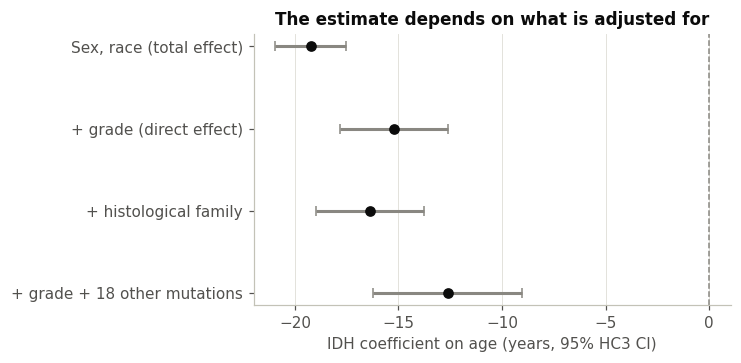

In [4]:
SETS = {"Sex, race (total effect)": COV,
        "+ grade (direct effect)": COV + ["Grade"],
        "+ histological family": COV + ["Family_Mixed glioma", "Family_Oligodendroglioma", "Family_Glioblastoma"],
        "+ grade + 18 other mutations": COV + ["Grade"] + OTHER_GENES}
rows, fits = [], {}
for name, adj in SETS.items():
    fit, table = causal.ols_table(df, "Age_at_diagnosis", ["IDH_mut"] + adj)
    fits[name] = table
    r = table.loc["IDH_mut"]
    rows.append({"Adjustment set": name, "IDH coefficient (years)": r["Coefficient"], "CI low": r["CI low"],
                 "CI high": r["CI high"], "R2": fit.rsquared, "Predictors": len(adj) + 1})
adj_table = pd.DataFrame(rows)
display(adj_table)
display(fits["+ grade (direct effect)"])
results["adjustment_sets"] = adj_table.to_dict(orient="records")
results["direct_model"] = fits["+ grade (direct effect)"].to_dict(orient="index")
reporting.save_table_tex(pd.DataFrame({"Adjustment set": adj_table["Adjustment set"],
                                       "IDH coefficient (years) [95% CI]": [f"{a:+.1f} [{b:+.1f}, {c:+.1f}]" for a, b, c in adj_table.iloc[:, 1:4].values],
                                       "R²": [f"{v:.3f}" for v in adj_table["R2"]]}),
                         "causal_adjustment_sets", column_format="lll")

fig, ax = plt.subplots(figsize=(5.6, 3.2))
yy = np.arange(len(adj_table))[::-1]
ax.errorbar(adj_table["IDH coefficient (years)"], yy, xerr=[adj_table["IDH coefficient (years)"] - adj_table["CI low"],
            adj_table["CI high"] - adj_table["IDH coefficient (years)"]], fmt="o", color=plotting.INK, ecolor=NEUTRAL, capsize=3)
ax.axvline(0, color=NEUTRAL, lw=1, ls="--")
ax.set_yticks(yy, adj_table["Adjustment set"]); ax.grid(axis="y", visible=False)
ax.set_xlabel("IDH coefficient on age (years, 95% HC3 CI)")
ax.set_title("The estimate depends on what is adjusted for")
plotting.save_figure(fig, "causal_adjustment_sets")
plt.show()

## 5. Mediation decomposition with bootstrap intervals

With OLS, the same patients and the same covariates, the total effect splits **exactly** into a direct and an indirect part (product of coefficients):

c (total) = c′ (direct) + a × b (indirect, through the grade),

where a is the effect of IDH on the grade (linear probability model) and b the effect of the grade on age adjusted for IDH. The identity is checked numerically. Percentile bootstrap intervals (2000 resamples of patients, seed 42) are reported for every quantity, including the proportion mediated a·b / c.

In [5]:
point = causal.mediation_decomposition(df, "IDH_mut", "Grade", "Age_at_diagnosis", COV)
print("Check c - (c' + ab) =", point["check c - (c' + ab)"])
assert abs(point["check c - (c' + ab)"]) < 1e-8
med = causal.bootstrap_mediation(df, "IDH_mut", "Grade", "Age_at_diagnosis", COV)
display(med)
results["mediation"] = med.to_dict(orient="index")
results["mediation_identity_error"] = point["check c - (c' + ab)"]
fmt = {k: ("{:.2f}" if "proportion" in k or "(a)" in k else "{:+.1f}") for k in med.index}
LABELS_MED = {"total (c)": "Total effect of IDH on age, c (years)",
              "IDH -> grade (a)": "Effect of IDH on P(GBM), a",
              "grade -> age (b)": "Effect of GBM on age given IDH, b (years)",
              "direct (c')": "Direct effect, c' (years)",
              "indirect (a*b)": "Indirect effect through the grade, a·b (years)",
              "proportion mediated": "Proportion mediated, a·b / c"}
reporting.save_table_tex(pd.DataFrame({"Quantity": [LABELS_MED[k] for k in med.index],
                                       "Estimate [95% bootstrap CI]": [f"{fmt[k].format(r['Estimate'])} [{fmt[k].format(r['CI low'])}, {fmt[k].format(r['CI high'])}]"
                                                                       for k, r in med.iterrows()]}),
                         "causal_mediation", column_format="ll")

Check c - (c' + ab) = 7.105427357601002e-14


,Estimate,CI low,CI high
total (c),-19.245,-20.958,-17.454
IDH -> grade (a),-0.731,-0.777,-0.685
grade -> age (b),5.516,2.894,8.341
direct (c'),-15.214,-17.797,-12.374
indirect (a*b),-4.031,-6.161,-2.094
proportion mediated,0.209,0.111,0.326


WindowsPath('C:/Users/ori/ML/results/tables/causal_mediation.tex')

## 6. Does the effect of IDH differ by grade?

The decomposition assumes that the effect of IDH on age is the same in LGG and GBM (no IDH × grade interaction). The interaction model tests that assumption; IDH-mutant GBM patients are few, so its interval is wide.

In [6]:
df["IDH_x_Grade"] = df["IDH_mut"] * df["Grade"]
fit_int, table_int = causal.ols_table(df, "Age_at_diagnosis", ["IDH_mut", "Grade", "IDH_x_Grade"] + COV)
display(table_int)
n_mut_gbm = int(((df["IDH_mut"] == 1) & (df["Grade"] == 1)).sum())
results["interaction"] = {"table": table_int.to_dict(orient="index"), "n_idh_mutant_gbm": n_mut_gbm}
reporting.save_table_tex(table_int.rename_axis("Term").reset_index().replace({"Term": {"const": "Intercept", "IDH_mut": "IDH mutation",
                         "IDH_x_Grade": "IDH x grade", "White": "Race white"}}), "causal_interaction", float_format="{:.3f}", column_format="lrrrr")
print(f"IDH-mutant GBM patients: {n_mut_gbm}")

,Coefficient,CI low,CI high,p-value
const,52.935,49.239,56.630,1.976e-173
IDH_mut,-13.201,-16.190,-10.212,4.875e-18
Grade,7.584,4.556,10.612,9.128e-07
IDH_x_Grade,-8.051,-14.022,-2.079,8.237e-03
Gender,0.621,-1.099,2.341,4.789e-01
White,1.664,-1.315,4.643,2.737e-01


IDH-mutant GBM patients: 25


## 7. Limitations and summary

- The diagram is an assumption. The decomposition is causal only if (i) there is no unmeasured common cause of IDH and age, (ii) no unmeasured common cause of the grade and the age at diagnosis (U), and (iii) the effects are linear and additive. (ii) is the weakest: the copy-number markers that define the grade today are missing from the data (PRDL Section 2).
- The grade is binary and was assigned with pre-2021 criteria, so part of it is measurement error, which biases the indirect effect towards zero.
- The total effect needs fewer assumptions than the split into direct and indirect parts.

Generated from the results above; saved in `results/logs/08_causal.json`.

In [7]:
m = med["Estimate"]
DK = "direct (c')"
rows_ = [
    ("Total effect of IDH on age (sex, race adjusted)", f"{m['total (c)']:+.1f} years [{med.loc['total (c)', 'CI low']:+.1f}, {med.loc['total (c)', 'CI high']:+.1f}]"),
    ("Direct effect (grade adjusted)", f"{m[DK]:+.1f} years [{med.loc[DK, 'CI low']:+.1f}, {med.loc[DK, 'CI high']:+.1f}]"),
    ("Indirect effect through the grade", f"{m['indirect (a*b)']:+.1f} years [{med.loc['indirect (a*b)', 'CI low']:+.1f}, {med.loc['indirect (a*b)', 'CI high']:+.1f}]"),
    ("Proportion mediated", f"{m['proportion mediated']:.2f} [{med.loc['proportion mediated', 'CI low']:.2f}, {med.loc['proportion mediated', 'CI high']:.2f}]"),
    ("Adjusting also for the histological family", f"{adj_table.iloc[2, 1]:+.1f} years"),
    ("IDH x grade interaction", f"{table_int.loc['IDH_x_Grade', 'Coefficient']:+.1f} years [{table_int.loc['IDH_x_Grade', 'CI low']:+.1f}, {table_int.loc['IDH_x_Grade', 'CI high']:+.1f}], {n_mut_gbm} IDH-mutant GBM"),
]
final_summary = pd.DataFrame(rows_, columns=["Topic", "Finding"])
with pd.option_context("display.max_colwidth", None):
    display(final_summary)
results["findings"] = dict(rows_)
path = reporting.save_json(results, "08_causal")
print("Saved", path.relative_to(config.ROOT))

,Topic,Finding
0,"Total effect of IDH on age (sex, race adjusted)","-19.2 years [-21.0, -17.5]"
1,Direct effect (grade adjusted),"-15.2 years [-17.8, -12.4]"
2,Indirect effect through the grade,"-4.0 years [-6.2, -2.1]"
3,Proportion mediated,"0.21 [0.11, 0.33]"
4,Adjusting also for the histological family,-16.4 years
5,IDH x grade interaction,"-8.1 years [-14.0, -2.1], 25 IDH-mutant GBM"


Saved results\logs\08_causal.json
